# Classification with Naive Bayes

In [1]:
import pandas as pd

## The watermelon dataset

In the following we use the Watermelon dataset from Zhou's textbook, where each record represents a watermelon with its features (color, sound, texture, etc) and with a boolean value indicating if the watermelon is ripe or not.
Notice:
Input features have different types: *color, root, sound, texture, umbilicus, surface* are categorical (have a finite number of nominal values that can only enumerated and compared by equality operators), while *density, sugar* are numerical (continuous) and mathematical operators can be used to transform their values.

We can easily read this CSV dataset using pandas.

In [2]:
dataset = pd.read_csv('datasets/watermelon-dataset.csv')
dataset

,ID,color,root,sound,texture,umbilicus,surface,density,sugar,ripe
0,1,green,curly,muffled,clear,hollow,hard,0.697,0.460,True
1,2,dark,curly,dull,clear,hollow,hard,0.774,0.376,True
2,3,dark,curly,muffled,clear,hollow,hard,0.634,0.264,True
3,4,green,curly,dull,clear,hollow,hard,0.608,0.318,True
4,5,light,curly,muffled,clear,hollow,hard,0.556,0.215,True
5,6,green,slightly curly,muffled,clear,slightly hollow,soft,0.403,0.237,True
6,7,dark,slightly curly,muffled,slightly blurry,slightly hollow,soft,0.481,0.149,True
7,8,dark,slightly curly,muffled,clear,slightly hollow,hard,0.437,0.211,True
8,9,dark,slightly curly,dull,slightly blurry,slightly hollow,hard,0.666,0.091,False
9,10,green,straight,crisp,clear,flat,soft,0.243,0.267,False


# Your work: what you have to do

- 1. Use `CategoricalNB` and `GaussianNB` from `scikit-learn` to build a Naive Bayes classifier on the watermelon dataset. For the estimated probabilities, consider the Laplace correction techniques.

- 2. Using the previously trained model, predict the ripe/unripe class of the test example proposed by the book:
*ID=T1, color=green, root=curly, sound=muffled, texture=clear, umbilicous=hollow, surface=hard, density=0.697, sugar=0.460. *

- 3. Giving the dataset size, consider now an hold-out technique in which you draw randomly a single test example and you train the model on the remaining examples.

- 4. Implement statistical tests (e.g. `ttest_rel` in [scipy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html)) to compare model trained at 3. to a Decision Tree on the same dataset with an hold-out method. Have the observed differences in predictive performance statistical  significance?

## Parte laboratorio fatta da meo su hold-out ##

#### Traduzione parte meo su moodle #### 

- Predirremo la classe di un esempio di test T1:

<ID=T1, color=green, root=curly, sound=muffled, texture=clear, umbilicous=hollow, surface=hard, density=0.697, sugar=0.460> <--questo è il primo esempio del dataset ID=1

- Poi, useremo la tecnica di hold-out:

- Confronteremo le performance predittive con la matrice di confusione e le curve ROC di naive Bayes e di decision trees con la tecnica di hold-out. 

- Troveremo se le differenze osservate di accuratezza predittiva con la tecnica di hold-out, tra naive Bayes e decision tree sono statisticamente significative.

##### Preparazione dati 

In [3]:
from sklearn.preprocessing import LabelEncoder
import numpy as np
# Separa features categoriche e numeriche
categorical_cols = ['color', 'root', 'sound', 'texture', 'umbilicus', 'surface']
numerical_cols = ['density', 'sugar']

X_categorical = dataset[categorical_cols]
X_numerical = dataset[numerical_cols]
y = dataset['ripe']

# Encoding delle features categoriche (testo → numeri)
label_encoders = {}
X_cat_encoded = X_categorical.copy()

for col in categorical_cols:
    le = LabelEncoder()
    X_cat_encoded[col] = le.fit_transform(X_categorical[col])
    label_encoders[col] = le

# Encoding del target
y_encoder = LabelEncoder()
y_encoded = y_encoder.fit_transform(y)

print(f"\nTarget encoding: {y.unique()} → {np.unique(y_encoded)}")



Target encoding: [ True False] → [0 1]


In [4]:
from sklearn.naive_bayes import CategoricalNB, GaussianNB
# Crea e addestra i classificatori con correzione di Laplace
categorical_nb = CategoricalNB(alpha=1.0, fit_prior=False)  # alpha=1.0 = correzione di Laplace
gaussian_nb = GaussianNB()

categorical_nb.fit(X_cat_encoded, y_encoded)
gaussian_nb.fit(X_numerical, y_encoded)

print(f"\nModelli addestrati:")
print(f"CategoricalNB: {X_cat_encoded.shape[1]} features categoriche")
print(f"GaussianNB: {X_numerical.shape[1]} features numeriche")
print(f"Correzione di Laplace: alpha={categorical_nb.alpha}")



Modelli addestrati:
CategoricalNB: 6 features categoriche
GaussianNB: 2 features numeriche
Correzione di Laplace: alpha=1.0


#### Combinazione probabilistica features categoriche e numeriche(gaussiane) con calcolo della accuracy

In [5]:
# Funzione per predizione combinata
def predict_combined(X_cat_encoded, X_num):
    prob_cat = categorical_nb.predict_proba(X_cat_encoded) 
    prob_num = gaussian_nb.predict_proba(X_num)
    
    # Combinazione diretta
    prob_combined = prob_cat * prob_num
    
    # Normalizza (necessario perché la moltiplicazione non preserva la normalizzazione)
    prob_combined = prob_combined / prob_combined.sum(axis=1, keepdims=True)
    
    predictions = np.argmax(prob_combined, axis=1)
    return predictions, prob_combined
# Test accuracy
predictions, probabilities = predict_combined(X_cat_encoded, X_numerical)
accuracy = np.mean(predictions == y_encoded)
print(f"\nAccuracy training: {accuracy:.10f}")


Accuracy training: 0.8235294118


## Punto 2 ##

In [6]:
test_example = {
    'color': 'green',
    'root': 'curly',
    'sound': 'muffled',
    'texture': 'clear',
    'umbilicus': 'hollow',
    'surface': 'hard',
    'density': 0.697,
    'sugar': 0.460
}
print("Esempio T1 da predire:{}".format(test_example))


Esempio T1 da predire:{'color': 'green', 'root': 'curly', 'sound': 'muffled', 'texture': 'clear', 'umbilicus': 'hollow', 'surface': 'hard', 'density': 0.697, 'sugar': 0.46}


In [7]:
# Prepara l'esempio per la predizione
# Encoding delle features categoriche
test_categorical = []
for col in categorical_cols:
    # Converti il valore usando il LabelEncoder già addestrato
    encoded_value = label_encoders[col].transform([test_example[col]])[0]
    test_categorical.append(encoded_value)
    print(f"{col}: '{test_example[col]}' → {encoded_value}")

test_numerical = [test_example['density'], test_example['sugar']]

color: 'green' → 1
root: 'curly' → 0
sound: 'muffled' → 2
texture: 'clear' → 1
umbilicus: 'hollow' → 1
surface: 'hard' → 0


In [8]:
# Predizione usando i modelli addestrati
# Crea DataFrame invece di array per mantenere i nomi delle colonne
test_cat_df = pd.DataFrame([test_categorical], columns=categorical_cols)
test_num_df = pd.DataFrame([test_numerical], columns=numerical_cols)

print(f"Test categoriche DataFrame:\n{test_cat_df}")
print(f"Test numeriche DataFrame:\n{test_num_df}")

# Probabilità da ogni modello
prob_cat = categorical_nb.predict_proba(test_cat_df)[0]
prob_num = gaussian_nb.predict_proba(test_num_df)[0]

print(f"\nProbabilità da features categoriche: {prob_cat}")
#prob_cat è un array contenente la probabilità per ogni classe categorica che sia FALSE (primo numero) o TRUE (secondo numero)
print(f"Probabilità da features numeriche: {prob_num}")
#prob_num è un array contenente la probabilità per ogni classe numerica che sia FALSE (primo numero) o TRUE (secondo numero)

Test categoriche DataFrame:
   color  root  sound  texture  umbilicus  surface
0      1     0      2        1          1        0
Test numeriche DataFrame:
   density  sugar
0    0.697   0.46

Probabilità da features categoriche: [0.04991258 0.95008742]
Probabilità da features numeriche: [0.04164757 0.95835243]


In [9]:
#Combinazione delle probabilità per la predizione finale
prob_combined = prob_cat * prob_num
# Normalizza le probabilità combinate perché la moltiplicazione 
# non preserva la normalizzazione, quindi sommano a 1
prob_combined = prob_combined / prob_combined.sum()

print(f"Probabilità combinate: {prob_combined}")

#Predizione finale
predicted_class_idx = np.argmax(prob_combined)
predicted_class = y_encoder.inverse_transform([predicted_class_idx])[0]
confidence = prob_combined[predicted_class_idx]

print(f"\nRISULTATO PREDIZIONE ESEMPIO T1")
print(f"Classe predetta: {predicted_class}")
print(f"Confidenza: {confidence:.3f}")
print(f"Probabilità FALSE: {prob_combined[0]:.3f}")
print(f"Probabilità TRUE: {prob_combined[1]:.3f}")

#Confronto con il valore reale
real_class = dataset.iloc[0]['ripe']
print(f"\nClasse reale ripe: {real_class}")
print(f"Predizione corretta: {'si' if predicted_class == real_class else 'no'}")

Probabilità combinate: [0.00227783 0.99772217]

RISULTATO PREDIZIONE ESEMPIO T1
Classe predetta: True
Confidenza: 0.998
Probabilità FALSE: 0.002
Probabilità TRUE: 0.998

Classe reale ripe: True
Predizione corretta: si


## Punto 3: Hold-out con singolo esempio di test ripetuto ##

Implementiamo la tecnica di hold-out estraendo casualmente un singolo esempio come test e addestrando sui rimanenti. Ripetiamo questo processo più volte per ottenere metriche stabili.

In [10]:
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
# Numero di ripetizioni hold-out
n_iterations = 100

nb_accuracies = []
nb_predictions_all = []
nb_true_labels_all = []
nb_probabilities_all = []

print("HOLD-OUT NAIVE BAYES")
print(f"Su {n_iterations} iterazioni di hold-out\n")

for i in range(n_iterations):
    #Estrai casualmente un indice per il test
    test_idx = np.random.randint(0, len(dataset))
    #Prendiamo tutti gli indici tranne quello di test idx != test_idx
    train_idx = [idx for idx in range(len(dataset)) if idx != test_idx]
    
    #Split train/test per la hold-out del test index corrente
    X_cat_train = X_cat_encoded.iloc[train_idx]
    X_cat_test = X_cat_encoded.iloc[[test_idx]]
    X_num_train = X_numerical.iloc[train_idx]
    X_num_test = X_numerical.iloc[[test_idx]]
    y_train = y_encoded[train_idx]
    y_test = y_encoded[[test_idx]]
    
    #Addestra modelli
    cat_nb_temp = CategoricalNB(alpha=1.0, fit_prior=False)
    #Fit prior a False per non considerare le frequenze delle classi, ad esempio in dataset sbilanciati
    gauss_nb_temp = GaussianNB()
    
    cat_nb_temp.fit(X_cat_train, y_train)
    gauss_nb_temp.fit(X_num_train, y_train)
    
    #Predizione combinata
    prob_cat = cat_nb_temp.predict_proba(X_cat_test)[0]
    prob_num = gauss_nb_temp.predict_proba(X_num_test)[0]
    prob_combined = prob_cat * prob_num
    prob_combined = prob_combined / prob_combined.sum()
    # P_combined = (P_cat * P_num) / sum(P_cat * P_num)
    
    prediction = np.argmax(prob_combined)
    
    #Salva risultati
    nb_accuracies.append(1 if prediction == y_test[0] else 0)
    nb_predictions_all.append(prediction)
    nb_true_labels_all.append(y_test[0])
    nb_probabilities_all.append(prob_combined[1])

nb_accuracies = np.array(nb_accuracies)
print(f"Naive Bayes - Accuracy media: {nb_accuracies.mean():.4f}")
print(f"Deviazione standard: {nb_accuracies.std():.4f}")
print(f"Range: {nb_accuracies.min():.4f} a {nb_accuracies.max():.4f}")

HOLD-OUT NAIVE BAYES
Su 100 iterazioni di hold-out

Naive Bayes - Accuracy media: 0.7300
Deviazione standard: 0.4440
Range: 0.0000 a 1.0000



MATRICE DI CONFUSIONE NAIVE BAYES
[[30 17]
 [10 43]]


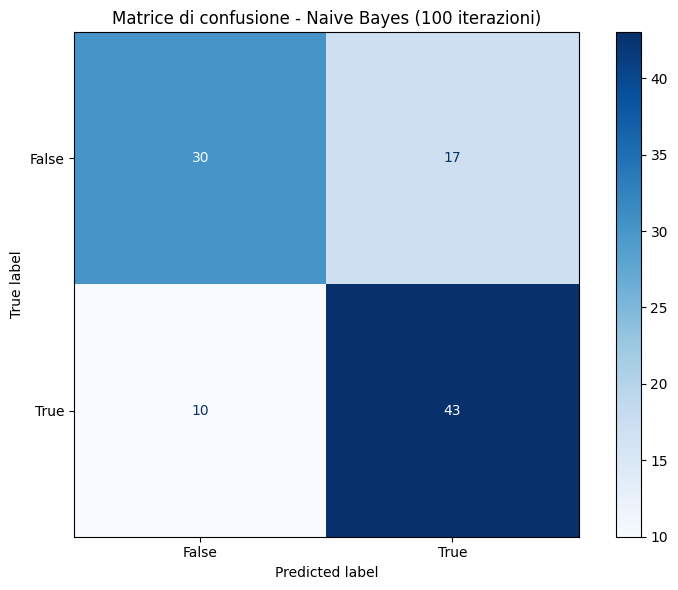

In [11]:
cm_nb = confusion_matrix(nb_true_labels_all, nb_predictions_all)
print("\nMATRICE DI CONFUSIONE NAIVE BAYES")
print(cm_nb)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nb, 
                              display_labels=y_encoder.classes_)
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title(f'Matrice di confusione - Naive Bayes ({n_iterations} iterazioni)')
plt.tight_layout()
plt.show()

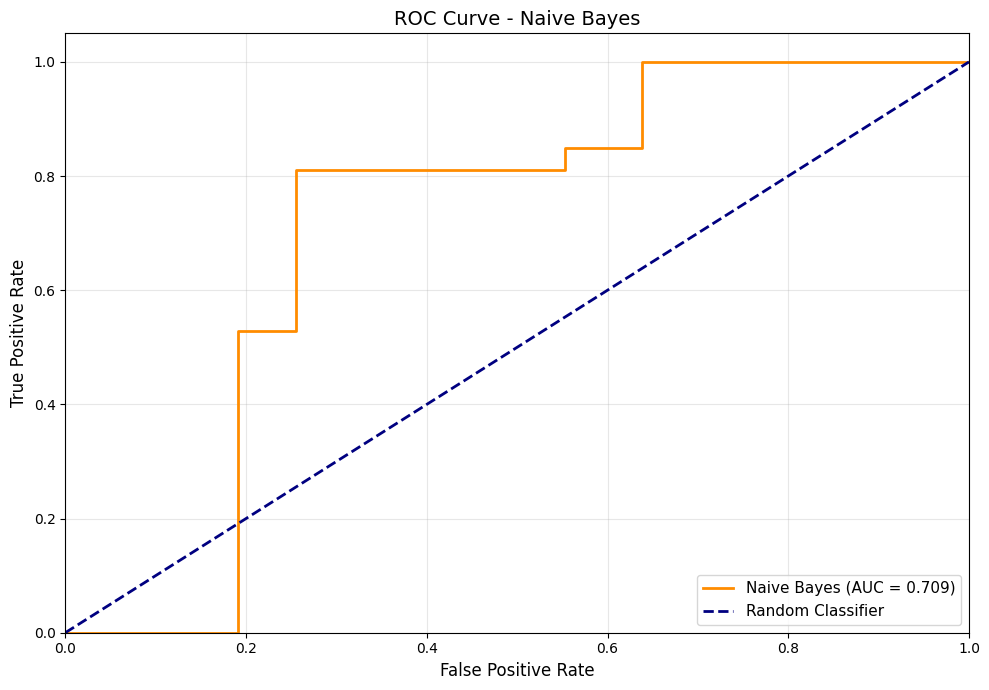


AUC Naive Bayes: 0.7094


In [12]:
# Curva ROC per Naive Bayes
fpr_nb, tpr_nb, _ = roc_curve(nb_true_labels_all, nb_probabilities_all)
roc_auc_nb = auc(fpr_nb, tpr_nb)

plt.figure(figsize=(10, 7))
plt.plot(fpr_nb, tpr_nb, color='darkorange', lw=2, 
         label=f'Naive Bayes (AUC = {roc_auc_nb:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve - Naive Bayes', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nAUC Naive Bayes: {roc_auc_nb:.4f}")

## Punto 4: Confronto con Decision Tree e test statistico ##

Addestriamo un Decision Tree con la stessa procedura di hold-out e confrontiamo le performance con un paired t-test.

In [13]:
np.random.seed(42)

dt_accuracies = []
dt_predictions_all = []
dt_true_labels_all = []
dt_probabilities_all = []

print("HOLD-OUT DECISION TREE")
print(f"Eseguendo {n_iterations} iterazioni di hold-out...\n")

X_complete = pd.concat([X_cat_encoded, X_numerical], axis=1)

for i in range(n_iterations):
    #Estrai stesso indice di test usato per NB
    test_idx = np.random.randint(0, len(dataset))
    train_idx = [idx for idx in range(len(dataset)) if idx != test_idx]
    
    #Split train/test
    X_train = X_complete.iloc[train_idx]
    X_test = X_complete.iloc[[test_idx]]
    y_train = y_encoded[train_idx]
    y_test = y_encoded[[test_idx]]
    
    #Addestra Decision Tree
    dt = DecisionTreeClassifier(random_state=42, max_depth=3, min_samples_leaf=2)
    dt.fit(X_train, y_train)
    
    #Predizione
    prediction = dt.predict(X_test)[0]
    prob = dt.predict_proba(X_test)[0]
    
    #Salva risultati
    dt_accuracies.append(1 if prediction == y_test[0] else 0)
    dt_predictions_all.append(prediction)
    dt_true_labels_all.append(y_test[0])
    dt_probabilities_all.append(prob[1])

dt_accuracies = np.array(dt_accuracies)
print(f"Decision Tree - Accuracy media: {dt_accuracies.mean():.4f}")
print(f"Deviazione standard: {dt_accuracies.std():.4f}")
print(f"Range: {dt_accuracies.min():.4f} a {dt_accuracies.max():.4f}")

HOLD-OUT DECISION TREE
Eseguendo 100 iterazioni di hold-out...

Decision Tree - Accuracy media: 0.8700
Deviazione standard: 0.3363
Range: 0.0000 a 1.0000



Matrice di confusione - Decision Tree:
[[44  3]
 [10 43]]


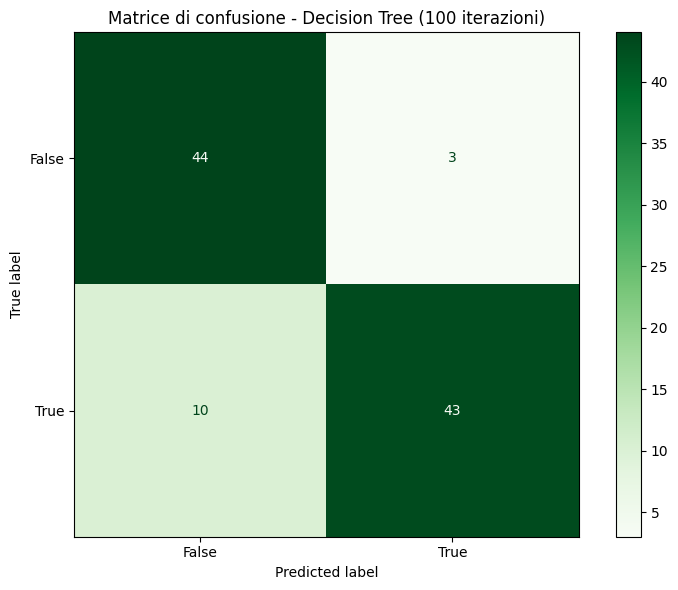

In [14]:
cm_dt = confusion_matrix(dt_true_labels_all, dt_predictions_all)
print("\nMatrice di confusione - Decision Tree:")
print(cm_dt)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, 
                              display_labels=y_encoder.classes_)
disp.plot(ax=ax, cmap='Greens', values_format='d')
plt.title(f'Matrice di confusione - Decision Tree ({n_iterations} iterazioni)')
plt.tight_layout()
plt.show()

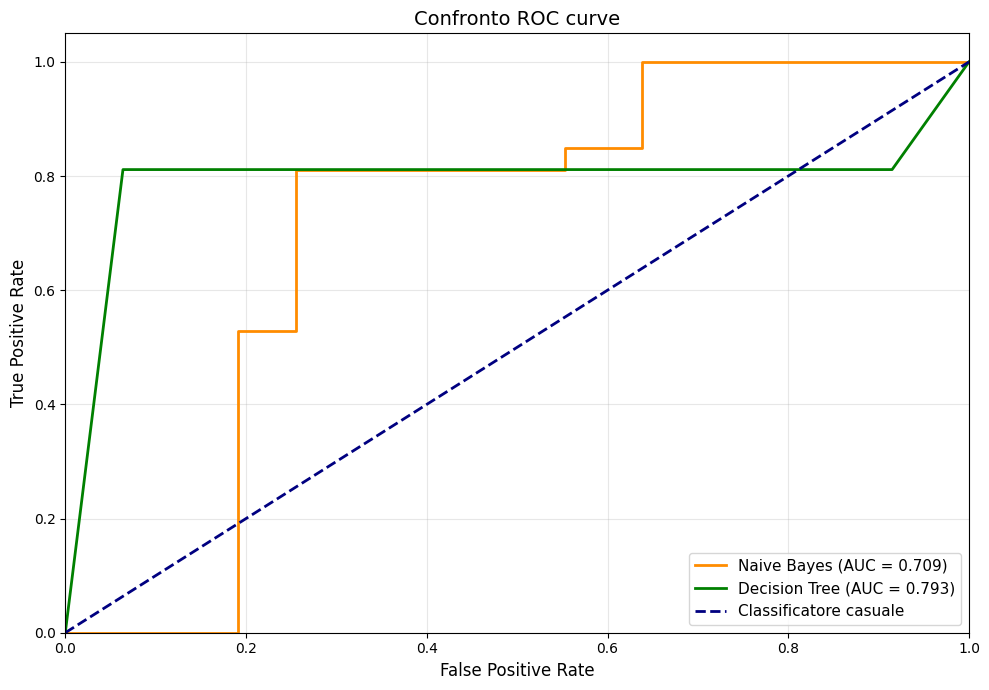


AUC Naive Bayes: 0.7094
AUC Decision Tree: 0.7935


In [15]:
fpr_dt, tpr_dt, _ = roc_curve(dt_true_labels_all, dt_probabilities_all)
roc_auc_dt = auc(fpr_dt, tpr_dt)

plt.figure(figsize=(10, 7))
plt.plot(fpr_nb, tpr_nb, color='darkorange', lw=2, 
         label=f'Naive Bayes (AUC = {roc_auc_nb:.3f})')
plt.plot(fpr_dt, tpr_dt, color='green', lw=2, 
         label=f'Decision Tree (AUC = {roc_auc_dt:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Classificatore casuale')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Confronto ROC curve', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nAUC Naive Bayes: {roc_auc_nb:.4f}")
print(f"AUC Decision Tree: {roc_auc_dt:.4f}")

In [ ]:
# Test statistico: Paired t-test
from scipy.stats import ttest_rel

t_statistic, p_value = ttest_rel(nb_accuracies, dt_accuracies)

print("TEST STATISTICO: PAIRED T-TEST")
print(f"\nNaive Bayes - Accuracy media: {nb_accuracies.mean():.4f}")
print(f"Decision Tree - Accuracy media: {dt_accuracies.mean():.4f}")
print(f"\nDifferenza media: {(nb_accuracies - dt_accuracies).mean():.4f}")
print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.6f}")

alpha = 0.05
print(f"\nLivello di significatività: alpha = {alpha}")

if p_value < alpha:
    print(f"Le differenze sono STATISTICAMENTE SIGNIFICATIVE (p < {alpha})")
    if nb_accuracies.mean() > dt_accuracies.mean():
        print("Naive Bayes performa meglio")
    else:
        print("Decision Tree performa meglio")
else:
    print(f"Le differenze NON sono statisticamente significative (p ≥ {alpha})")
    print("Non c'è evidenza di una differenza significativa tra i due modelli")

TEST STATISTICO: PAIRED T-TEST

Naive Bayes - Accuracy media: 0.7300 (+/-0.4440)
Decision Tree - Accuracy media: 0.8700 (+/-0.3363)

Differenza media: -0.1400
T-statistic: -4.0145
P-value: 0.000116

Livello di significatività: alpha = 0.05
Le differenze sono STATISTICAMENTE SIGNIFICATIVE (p < 0.05)
Decision Tree performa meglio


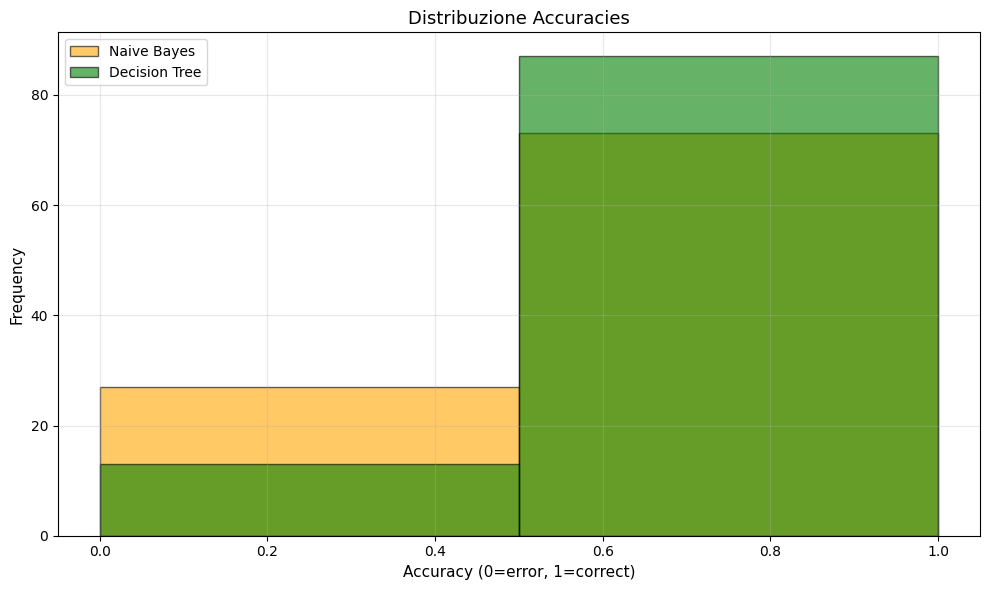

In [17]:
#Visualizzazione distribuzione accuracies
fig, ax = plt.subplots(figsize=(10, 6))

#Istogrammi
ax.hist(nb_accuracies, bins=2, alpha=0.6, label='Naive Bayes', color='orange', edgecolor='black')
ax.hist(dt_accuracies, bins=2, alpha=0.6, label='Decision Tree', color='green', edgecolor='black')
ax.set_xlabel('Accuracy (0=error, 1=correct)', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.set_title('Distribuzione Accuracies', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
#Questi istogrammi mostrano la distribuzione delle accuratezze ottenute dai due modelli sulle 100 iterazioni di hold-out.
#Ci aspettiamo che nelle due barre di accuratezza (0 e 1) ci siano differenze significative in altezza se 
#un modello performa meglio dell'altro.

In [ ]:
results_df = pd.DataFrame({
    'Iteration': range(1, n_iterations + 1),
    'NB_Accuracy': nb_accuracies,
    'DT_Accuracy': dt_accuracies,
    'NB_Prediction': nb_predictions_all,
    'DT_Prediction': dt_predictions_all,
    'True_Label': nb_true_labels_all
})

# Summary finale
print("\nSUMMARY FINALE")
print(f"\nMetriche Naive Bayes:")
print(f"\tAccuracy: {nb_accuracies.mean():.4f}")
print(f"\tAUC: {roc_auc_nb:.4f}")
print(f"\nMetriche Decision Tree:")
print(f"\tAccuracy: {dt_accuracies.mean():.4f}")
print(f"\tAUC: {roc_auc_dt:.4f}")
print(f"\nTest statistico (paired t-test):")
print(f"P-value: {p_value:.6f}")
print(f"Significatività statistica: {'SI' if p_value < 0.05 else 'NO'}")



SUMMARY FINALE

Metriche Naive Bayes:
	Accuracy: 0.7300 +/- 0.4440
	AUC: 0.7094

Metriche Decision Tree:
	Accuracy: 0.8700 +/- 0.3363
	AUC: 0.7935

Test statistico (paired t-test):
P-value: 0.000116
Significatività statistica: SI


In questo caso abbiamo pochi esempi con le feature non indipendenti tra di loro. Quindi Naive-Bayes performa peggio di un decision tree che al contrario può catturare queste dipendenze